# Importar Bibliotecas Necesarias
Importar pandas, numpy, sklearn (Pipeline, RandomForestClassifier, OneHotEncoder, SimpleImputer, train_test_split, classification_report, accuracy_score), joblib y las funciones personalizadas necesarias de los módulos utils.

In [1]:
import pandas as pd
import numpy as np
from statistics import mean
import os
import sys
import joblib # For saving the model
import json
from datetime import timezone

# Scikit-learn imports
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Ruta absoluta al directorio src
src_path = os.path.abspath("../src") # Adjust if the notebook location changes relative to src
if src_path not in sys.path:
    sys.path.append(src_path)

# Import custom utility functions
from utils.exploration_utils import (
    read_csv_files,
    preprocess_data,
    generate_target_variable,
    engineer_features
)
from utils.support_resistance import calculate_progressive_support_resistance, calcular_metricas_fila
from utils.viz_utils import plot_candlestick_with_clusters_plotly, analizar_metricas_por_umbral
from sklearn.cluster import KMeans # For clustering steps if included in pipeline

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100) # Adjust as needed

# Cargar Datos Iniciales
Cargar el conjunto de datos principal (por ejemplo, desde un archivo parquet '../data/parquet/EURUSD/EURUSD_5mins.parquet').

In [2]:
# Read Data from CSV files:
folder_path = '../data/EURUSD/5mins' # Define the folder containing CSV files
print(f"Attempting to load data from CSV files in: {folder_path}")
import pytz # Ensure pytz is imported if used in checks

try:
    # Check if the directory exists
    if not os.path.isdir(folder_path):
         raise FileNotFoundError(f"Error: Directory not found at {folder_path}. Please check the path.")

    df_EURUSD_5min = read_csv_files(folder_path) # Use the utility function to read CSVs

    # Check if data was loaded
    if df_EURUSD_5min.empty:
        print("Warning: No data loaded. The DataFrame is empty. Check the CSV files or the read_csv_files function.")
    else:
        print(f"Data loaded successfully from CSVs in {folder_path}")
        print(f"Initial DataFrame shape: {df_EURUSD_5min.shape}")

        # Apply preprocessing (includes timezone parsing and UTC conversion)
        print("Applying preprocessing (preprocess_data)...")
        # preprocess_data now handles parsing 'YYYYMMDD HH:MM:SS TZ' and converting to UTC
        df_EURUSD_5min = preprocess_data(df_EURUSD_5min)
        print(f"DataFrame shape after preprocess_data: {df_EURUSD_5min.shape}")

        # Verify the result of preprocess_data
        if 'datetime' not in df_EURUSD_5min.columns:
             raise KeyError("Critical Error: 'datetime' column not found after preprocess_data.")
        if not pd.api.types.is_datetime64_any_dtype(df_EURUSD_5min['datetime']):
             print("Warning: 'datetime' column is not in a recognized datetime format after preprocess_data.")
        # Check if the timezone is specifically UTC
        elif df_EURUSD_5min['datetime'].dt.tz is None or df_EURUSD_5min['datetime'].dt.tz != timezone.utc:
             print(f"Warning: 'datetime' column is not timezone-aware UTC after preprocess_data. Found: {df_EURUSD_5min['datetime'].dt.tz}")
        else:
             print("'datetime' column successfully processed to timezone-aware UTC by preprocess_data.")

        # Optional: Check for NaT values introduced during preprocessing
        nat_count = df_EURUSD_5min['datetime'].isna().sum()
        if nat_count > 0:
            print(f"Warning: {nat_count} rows have NaT in 'datetime' after preprocessing. Consider dropping them if necessary.")
            # df_EURUSD_5min.dropna(subset=['datetime'], inplace=True)

        # Sorting is already done inside preprocess_data, no need to repeat
        print("DataFrame is sorted by UTC datetime within preprocess_data.")

except FileNotFoundError as fnf_error:
     print(fnf_error)
     raise # Re-raise the exception to stop the notebook if the directory is critical

except KeyError as ke:
     print(ke) # Print the specific KeyError message
     raise # Re-raise to indicate failure

except Exception as e:
    print(f"An unexpected error occurred during data loading or preprocessing: {e}")
    import traceback
    traceback.print_exc() # Print full traceback for unexpected errors
    raise # Re-raise to indicate failure

# Display head if data loaded successfully
if 'df_EURUSD_5min' in locals() and not df_EURUSD_5min.empty:
    print("\nDisplaying first few rows of the loaded and preprocessed data (datetime is UTC):")
    df_EURUSD_5min.head()
else:
    print("\nCould not display head as DataFrame is not available or empty.")

Attempting to load data from CSV files in: ../data/EURUSD/5mins
Data loaded successfully from CSVs in ../data/EURUSD/5mins
Initial DataFrame shape: (1102016, 7)
Applying preprocessing (preprocess_data)...
Starting preprocessing...
Convirtiendo fechas/horas parseadas a UTC...
Extrayendo componentes de fecha/hora desde UTC...
Ordenando DataFrame por fecha/hora UTC...
Preprocesamiento completado. DataFrame ordenado por fecha/hora UTC.
DataFrame shape after preprocess_data: (1102016, 14)
DataFrame is sorted by UTC datetime within preprocess_data.

Displaying first few rows of the loaded and preprocessed data (datetime is UTC):


In [3]:
df_EURUSD_5min.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1102016 entries, 0 to 1102015
Data columns (total 14 columns):
 #   Column     Non-Null Count    Dtype              
---  ------     --------------    -----              
 0   open       1102016 non-null  float64            
 1   high       1102016 non-null  float64            
 2   low        1102016 non-null  float64            
 3   close      1102016 non-null  float64            
 4   volume     1102016 non-null  int64              
 5   barCount   1102016 non-null  int64              
 6   datetime   1102016 non-null  datetime64[ns, UTC]
 7   Year       1102016 non-null  int64              
 8   Month      1102016 non-null  object             
 9   Day        1102016 non-null  int64              
 10  Date       1102016 non-null  object             
 11  Hour       1102016 non-null  int64              
 12  Minute     1102016 non-null  int64              
 13  DayOfWeek  1102016 non-null  int64              
dtypes: datetime64[ns, 

In [ ]:
# Define the target variable name
TARGET_VARIABLE = 'multiclass_target'

# Ensure 'datetime' column exists and is sorted
df_EURUSD_5min = df_EURUSD_5min.sort_values('datetime').reset_index(drop=True)

PIPS_OBJETIVO_GENERACION = 8 # Valor de pips para objetivo
PIPS_STOP_GENERACION = 2    # Valor de pips para stop

# Generate target (this modifies the DataFrame)
df_processed = generate_target_variable(df_EURUSD_5min, 
                                        pips_objetivo=PIPS_OBJETIVO_GENERACION, 
                                        pips_stop=PIPS_STOP_GENERACION, 
                                        future_periods=12)

# Drop rows where target could not be calculated (usually at the end due to future lookahead)
df_processed = df_processed.dropna(subset=[TARGET_VARIABLE, 'compra_resultado', 'venta_resultado']) # Also drop rows missing evaluation results
# Also drop rows where future values were NaN if needed for feature engineering
df_processed = df_processed.dropna(subset=['future_high_values', 'future_low_values', 'future_close_values'], how='any')


# Define the split date
split_date_train_end = "2023-12-31" 
split_date_test_end = "2024-12-31"


# Convert split_dates to the same timezone as the data if necessary
if df_processed['datetime'].dt.tz is not None:
    tz_info = df_processed['datetime'].dt.tz
    # Use pd.Timestamp and specify end of day for inclusive range
    split_datetime_train_end = pd.Timestamp(split_date_train_end, tz=tz_info).replace(hour=23, minute=59, second=59)
    split_datetime_test_end = pd.Timestamp(split_date_test_end, tz=tz_info).replace(hour=23, minute=59, second=59)
else:
    split_datetime_train_end = pd.Timestamp(split_date_train_end).replace(hour=23, minute=59, second=59)
    split_datetime_test_end = pd.Timestamp(split_date_test_end).replace(hour=23, minute=59, second=59)



# Split data into Train, Test, and OOT (Validation)
df_train = df_processed[df_processed['datetime'] <= split_datetime_train_end].copy()
df_test = df_processed[(df_processed['datetime'] > split_datetime_train_end) &
                       (df_processed['datetime'] <= split_datetime_test_end)].copy()
df_oot = df_processed[df_processed['datetime'] > split_datetime_test_end].copy()

# Separate features (X) and target (y) for each set
columns_to_drop_for_X = [
    TARGET_VARIABLE,
    'datetime', 'open','close','high', 'low','volume',
    'future_high_values', 'future_low_values', 'future_close_values',
    'barCount', 'Year', 'Minute', 'compra_velas', 'compra_pips',
    'venta_velas', 'venta_pips'
]
# X includes all columns needed for the pipeline's feature engineering steps
# y is just the target variable column
X_train = df_train.drop(columns=columns_to_drop_for_X, errors='ignore') 
y_train = df_train[TARGET_VARIABLE]

X_test = df_test.drop(columns=columns_to_drop_for_X, errors='ignore')
y_test = df_test[TARGET_VARIABLE]

X_oot = df_oot.drop(columns=columns_to_drop_for_X, errors='ignore')
y_oot = df_oot[TARGET_VARIABLE]


DEBUG_MODE = False # Set to False for full training run
# Adjust sample size as needed - smaller means faster debugging
DEBUG_SAMPLE_SIZE = 50000 # Try starting with 5000-10000 rows

if DEBUG_MODE and len(X_train) > DEBUG_SAMPLE_SIZE:
    print(f"--- DEBUG MODE ACTIVE: Using subset of {DEBUG_SAMPLE_SIZE} training samples ---")
    # Ensure consistent sampling if needed, add random_state
    X_train_debug = X_train.sample(n=DEBUG_SAMPLE_SIZE, random_state=42)
    # Keep alignment using the index of the sampled X_train
    y_train_debug = y_train.loc[X_train_debug.index]
    print(f"   X_train_debug shape: {X_train_debug.shape}")
    print(f"   y_train_debug shape: {y_train_debug.shape}")
else:
    # If not in debug mode or sample is too small, use original data
    X_train_debug = X_train
    y_train_debug = y_train
    print("--- DEBUG MODE INACTIVE or sample size too large: Using full training set ---")

# Clean up large intermediate dataframe if memory is a concern
# del df_processed
# import gc
# gc.collect()

print(f"Data split completed:")
print(f"Training set shape:   X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Test set shape:       X_test {X_test.shape}, y_test {y_test.shape}")
print(f"OOT (Validation) set shape: X_oot {X_oot.shape}, y_oot {y_oot.shape}")

print(f"\nTraining target distribution:\n{y_train.value_counts(normalize=True)}")
print(f"\nTest target distribution:\n{y_test.value_counts(normalize=True)}")
print(f"\nOOT target distribution:\n{y_oot.value_counts(normalize=True)}")

# Display first few rows of training features
print("\nFirst few rows of X_train:")
X_train.head()

Generating target variable (pips_objetivo=8, pips_stop=2, future_periods=12)...
Evaluating trading scenarios...
Target variable 'multiclass_target' created.
--- DEBUG MODE INACTIVE or sample size too large: Using full training set ---
Data split completed:
Training set shape:   X_train (1009598, 23), y_train (1009598,)
Test set shape:       X_test (72174, 23), y_test (72174,)
OOT (Validation) set shape: X_oot (20244, 23), y_oot (20244,)

Training target distribution:
no_objetivo_alcanzado        0.805479
objetivo_compra_alcanzado    0.098740
objetivo_venta_alcanzado     0.095781
Name: multiclass_target, dtype: float64

Test target distribution:
no_objetivo_alcanzado        0.852828
objetivo_venta_alcanzado     0.074016
objetivo_compra_alcanzado    0.073157
Name: multiclass_target, dtype: float64

OOT target distribution:
no_objetivo_alcanzado        0.784134
objetivo_venta_alcanzado     0.110008
objetivo_compra_alcanzado    0.105859
Name: multiclass_target, dtype: float64

First few ro

,open,high,low,close,volume,barCount,datetime,Year,Month,Day,Date,Hour,Minute,DayOfWeek,future_high_values,future_low_values,future_close_values,compra_resultado,compra_velas,compra_pips,venta_resultado,venta_velas,venta_pips
0,1.43085,1.43090,1.43080,1.43090,-1,-1,2010-01-03 22:15:00+00:00,2010,201001,3,20100103,22,15,6,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",SIN_ALCANCE,12,0.0,SIN_ALCANCE,12,0.0
1,1.43090,1.43175,1.43090,1.43170,-1,-1,2010-01-03 22:20:00+00:00,2010,201001,3,20100103,22,20,6,"[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1....","[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.4...","[1.4317, 1.4317, 1.4311, 1.43245, 1.43225, 1.4...",STOP_ALCANZADO,1,-8.0,OBJETIVO_ALCANZADO,1,8.0
2,1.43170,1.43180,1.43150,1.43170,-1,-1,2010-01-03 22:25:00+00:00,2010,201001,3,20100103,22,25,6,"[1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1....","[1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1....","[1.4317, 1.4311, 1.43245, 1.43225, 1.4326, 1.4...",STOP_ALCANZADO,1,-2.0,STOP_ALCANZADO,3,-11.5
3,1.43170,1.43180,1.43095,1.43110,-1,-1,2010-01-03 22:30:00+00:00,2010,201001,3,20100103,22,30,6,"[1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1...","[1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1....","[1.4311, 1.43245, 1.43225, 1.4326, 1.4336, 1.4...",OBJETIVO_ALCANZADO,2,17.5,STOP_ALCANZADO,1,-7.0
4,1.43110,1.43285,1.43110,1.43245,-1,-1,2010-01-03 22:35:00+00:00,2010,201001,3,20100103,22,35,6,"[1.43285, 1.43255, 1.43265, 1.43365, 1.43375, ...","[1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1....","[1.43245, 1.43225, 1.4326, 1.4336, 1.43255, 1....",STOP_ALCANZADO,1,-13.5,STOP_ALCANZADO,1,-4.0


In [5]:
# --- Reemplazar contenido de la celda 984e01f7 ---

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import TruncatedSVD 

# --- Preprocesadores ---

# Numerical Preprocessor (para columnas numéricas estándar)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Categorical Preprocessor (para OHE de otras variables categóricas si las hay)
categorical_ohe_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# --- NUEVO: Hashing Transformer para la columna 'pattern' ---
# Define el número deseado de características de salida (ej. 10, 20, 50...)
N_HASH_FEATURES = 100 # Ajusta este valor según sea necesario


N_EMBEDDING_COMPONENTS = 30 # Ajusta este valor (ej. 50, 100, etc.)

pattern_embedding_transformer = Pipeline(steps=[
    # Paso 1: Imputar NaNs si los hubiera (aunque ya filtramos antes)
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    # Paso 2: OneHotEncode la columna 'pattern'. Salida dispersa es eficiente aquí.
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
    # Paso 3: Aplicar TruncatedSVD para reducir dimensionalidad y crear embeddings densos
    ('svd', TruncatedSVD(n_components=N_EMBEDDING_COMPONENTS, random_state=42))
    # Opcional: Escalar los embeddings si es necesario para el modelo posterior
    # ('scaler', StandardScaler(with_mean=False)) # SVD ya centra los datos
])

# --- Define Model (sin cambios) ---
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=100,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced',
    max_features='sqrt'
)

print("Pipeline components defined (numeric_transformer, categorical_ohe_transformer, pattern_hasher_transformer, rf_model).")
print(f"Pattern column will be hashed into {N_HASH_FEATURES} features.")
print("The full preprocessor and simplified_pipeline will be created in the training cell.")


Pipeline components defined (numeric_transformer, categorical_ohe_transformer, pattern_hasher_transformer, rf_model).
Pattern column will be hashed into 100 features.
The full preprocessor and simplified_pipeline will be created in the training cell.


In [ ]:
# --- Reemplazar contenido de la celda 7c0ee38a ---

import importlib
import utils.exploration_utils
importlib.reload(utils.exploration_utils)
from utils.exploration_utils import engineer_features
import traceback
import os
import joblib
import json

print("--- Model Loading / Training Cell ---")

# --- Parámetros y Rutas ---
# Estos parámetros se usarán si entrenamos, o se intentarán cargar de metadata si cargamos el modelo
N_CANDLES_PARAM = 15
N_CLUSTERS_PARAM = 5
# N_EMBEDDING_COMPONENTS ya está definido en la celda 984e01f7
# TARGET_VARIABLE ya está definido en la celda 5fb60a74

model_dir = '../models/EURUSD'
model_filename = 'forex_rf_pipeline_eurusd_5mins.joblib'
metadata_filename = 'forex_rf_pipeline_eurusd_5min_metadata.json'
clusterer_filename = 'forex_candle_clusterer_eurusd_5mins.joblib'

model_filepath = os.path.join(model_dir, model_filename)
metadata_filepath = os.path.join(model_dir, metadata_filename)
clusterer_filepath = os.path.join(model_dir, clusterer_filename)

# Inicializar variables
model_loaded = False
simplified_pipeline = None
fitted_clusterer = None
metadata = None
final_numerical_features = []
other_categorical_features = []
pattern_feature = []

# --- Intentar Cargar Modelo Existente ---
if os.path.exists(model_filepath) and os.path.exists(clusterer_filepath) and os.path.exists(metadata_filepath):
    print(f"Found existing model files in {model_dir}. Attempting to load...")
    try:
        simplified_pipeline = joblib.load(model_filepath)
        print(f"  - Pipeline loaded successfully from: {model_filepath}")

        fitted_clusterer = joblib.load(clusterer_filepath)
        print(f"  - Clusterer loaded successfully from: {clusterer_filepath}")

        with open(metadata_filepath, 'r') as f:
            metadata = json.load(f)
        print(f"  - Metadata loaded successfully from: {metadata_filepath}")

        # Restaurar parámetros y listas de características desde metadata
        # Sobrescribir los valores por defecto si están en metadata
        N_CANDLES_PARAM = metadata.get('n_candles_param', N_CANDLES_PARAM)
        N_CLUSTERS_PARAM = metadata.get('n_clusters_param', N_CLUSTERS_PARAM)
        N_EMBEDDING_COMPONENTS = metadata.get('n_embedding_components', N_EMBEDDING_COMPONENTS) # Asegurar consistencia
        final_numerical_features = metadata.get('final_numerical_features', [])
        other_categorical_features = metadata.get('other_categorical_features', [])
        pattern_feature = metadata.get('pattern_feature', [])

        # Verificar que las listas de características se cargaron
        if not final_numerical_features or not other_categorical_features or not pattern_feature:
             print("  - Warning: Feature lists not found or empty in metadata. Feature importance analysis might fail.")
        else:
             print(f"  - Loaded {len(final_numerical_features)} numerical features.")
             print(f"  - Loaded {len(other_categorical_features)} OHE features.")
             print(f"  - Loaded {len(pattern_feature)} pattern feature.")


        model_loaded = True
        print("\nModel, clusterer, and metadata loaded successfully. Skipping training.")

    except Exception as e:
        print(f"\nError loading existing model files: {e}")
        print("Proceeding with training a new model.")
        model_loaded = False
        simplified_pipeline = None # Resetear en caso de error parcial
        fitted_clusterer = None
        metadata = None
else:
    print(f"Model files not found in {model_dir}. Proceeding with training a new model.")
    model_loaded = False

# --- Entrenar Nuevo Modelo (si no se cargó uno) ---
if not model_loaded:
    print("\nStarting feature engineering and pipeline training...")
    try:
        # --- 1. Ingeniería de Características Externa (Ajustar Clusterer) ---
        print("   Running engineer_features (fitting clusterer)...")
        # Usar X_train completo (o X_train_debug si está activo)
        X_to_engineer = X_train_debug if 'DEBUG_MODE' in locals() and DEBUG_MODE else X_train
        y_to_align = y_train_debug if 'DEBUG_MODE' in locals() and DEBUG_MODE else y_train

        X_engineered_train, fitted_clusterer = engineer_features(
            X_to_engineer,
            n_candles=N_CANDLES_PARAM,
            n_clusters=N_CLUSTERS_PARAM,
            min_pattern_threshold=100, # Asegúrate que CandleClusterer tenga estos params
            fit_clusterer=True, # Ajustar el clusterer aquí
            random_state=42
        )
        print(f"   Shape after external engineering: {X_engineered_train.shape}")
        if fitted_clusterer: print("   CandleClusterer fitted successfully.")
        else: raise ValueError("Clusterer fitting failed.")

        # --- 2. Identificar Filas Válidas y Filtrar ---
        print("   Identifying valid (non-NaN) rows after engineering...")
        essential_cols = ['pattern'] # Columna necesaria para embedding
        valid_rows_index = X_engineered_train.dropna(subset=essential_cols).index
        original_rows = len(X_engineered_train)
        valid_rows_count = len(valid_rows_index)
        print(f"   Found {valid_rows_count} valid rows out of {original_rows} ({original_rows - valid_rows_count} rows removed for training).")

        X_train_clean = X_engineered_train.loc[valid_rows_index]
        y_train_clean = y_to_align.loc[valid_rows_index] # Alinear y con X filtrado

        print(f"   Shape of X_train_clean: {X_train_clean.shape}")
        print(f"   Shape of y_train_clean: {y_train_clean.shape}")

        # --- 3. Definir Listas Finales de Características (Dinámicamente) ---
        print("   Defining final feature lists...")
        potential_numeric_features = X_train_clean.select_dtypes(include=np.number).columns.tolist()
        potential_categorical_features = X_train_clean.select_dtypes(exclude=np.number).columns.tolist()

        other_categorical_features = [
            col for col in ['DayOfWeek', 'Month', 'Day', 'Hour', 'candle_cluster'] # Añadir otras si existen
            if col in X_train_clean.columns
        ]
        pattern_feature = ['pattern'] if 'pattern' in X_train_clean.columns else []
        unwanted_features = ['datetime', 'open','close','high', 'low','volume',
                             'future_high_values', 'future_low_values', 'future_close_values',
                             'barCount', 'Year', 'Minute', 'compra_velas', 'compra_pips',
                             'venta_velas', 'venta_pips']

        final_numerical_features = [
            col for col in potential_numeric_features
            if col not in other_categorical_features and col not in pattern_feature and col not in unwanted_features
        ]

        print(f"   Final Numerical Features ({len(final_numerical_features)}): {final_numerical_features[:5]}...")
        print(f"   Final Categorical Features for OHE ({len(other_categorical_features)}): {other_categorical_features}")
        if pattern_feature: print(f"   Pattern Feature for Embedding: {pattern_feature}")
        else: print("   Warning: 'pattern' column not found for embedding.")

        # --- 4. Crear Preprocesador y Pipeline Simplificado ---
        print("   Creating final preprocessor and pipeline...")
        # Reutilizar transformadores definidos en la celda 984e01f7
        transformers_list = [
            ('num', numeric_transformer, final_numerical_features)
        ]
        if other_categorical_features:
            transformers_list.append(('cat_ohe', categorical_ohe_transformer, other_categorical_features))
        if pattern_feature:
            # Asegurarse que N_EMBEDDING_COMPONENTS está definido
            if 'N_EMBEDDING_COMPONENTS' not in locals(): raise NameError("N_EMBEDDING_COMPONENTS not defined")
            # Recrear el pattern_embedding_transformer por si acaso (aunque debería estar definido)
            pattern_embedding_transformer = Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
                ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
                ('svd', TruncatedSVD(n_components=N_EMBEDDING_COMPONENTS, random_state=42))
            ])
            transformers_list.append(('pattern_embed', pattern_embedding_transformer, pattern_feature))

        preprocessor = ColumnTransformer(
            transformers=transformers_list,
            remainder='drop',
            verbose=False # Reducir verbosidad
        )

        # Reutilizar rf_model definido en la celda 984e01f7
        simplified_pipeline = Pipeline(steps=[
            ('preprocessing', preprocessor),
            ('classifier', rf_model)
        ], verbose=False) # Reducir verbosidad

        print("\\nSimplified pipeline created:")
        # print(simplified_pipeline) # Opcional: imprimir estructura

        # --- 5. Entrenar Pipeline Simplificado ---
        print("\\nStarting simplified pipeline training...")
        simplified_pipeline.fit(X_train_clean, y_train_clean)
        print("Simplified pipeline training completed successfully.")

        # --- 6. Preparar Metadata para Guardar ---
        print("   Preparing metadata...")
        metadata = {
            'description': 'Simplified Scikit-Learn pipeline for EURUSD 5min Forex prediction (RF). Includes feature engineering and preprocessing.',
            'target_variable': TARGET_VARIABLE,
            'model_step_name': 'classifier',
            'class_labels': list(simplified_pipeline.classes_),
            'split_date_train_end': split_date_train_end, # Definido en celda 5fb60a74
            'n_candles_param': N_CANDLES_PARAM,
            'n_clusters_param': N_CLUSTERS_PARAM,
            'n_embedding_components': N_EMBEDDING_COMPONENTS,
            'final_numerical_features': final_numerical_features, # Guardar lista
            'other_categorical_features': other_categorical_features, # Guardar lista
            'pattern_feature': pattern_feature, # Guardar lista
        }
        print("   Metadata prepared.")

    except Exception as e:
        print(f"An error occurred during training preparation or fitting: {e}")
        traceback.print_exc()
        # Asegurarse que las variables clave estén None si falla el entrenamiento
        simplified_pipeline = None
        fitted_clusterer = None
        metadata = None

# --- Mensaje Final de la Celda ---
if simplified_pipeline and fitted_clusterer and metadata:
    print("\n--- Load/Train Cell Finished: Pipeline, Clusterer, and Metadata are available. ---")
    if model_loaded:
        print("(Using pre-loaded model)")
    else:
        print("(Using newly trained model)")
else:
    print("\n--- Load/Train Cell Finished: Error occurred, model/clusterer/metadata might not be available. Check logs above. ---")


--- Model Loading / Training Cell ---
Model files not found in ../models. Proceeding with training a new model.

Starting feature engineering and pipeline training...
   Running engineer_features (fitting clusterer)...
--- Starting Feature Engineering ---
>>> Starting step: apply_technical_indicators


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1012: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_shrinking_histogram_above_zero"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1019: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_buy_signal"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1024: PerformanceW

<<< Finished step: apply_technical_indicators
>>> Starting step: apply_candle_features (n_candles=15)


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:

<<< Finished step: apply_candle_features
   Fitting and transforming with NEW CandleClusterer...
>>> Starting step: CandleClusterer.fit (k=5)
   KMeans fitted.
   Fitting pattern mapping...
   Pattern mapping created. 0 rare patterns will be mapped.
<<< Finished step: CandleClusterer.fit
>>> Starting step: CandleClusterer.transform
   Candle clusters predicted.
   Basic patterns created.
   No pattern mapping to apply (or mapping is empty).
<<< Finished step: CandleClusterer.transform
>>> Starting step: replace_inf_with_nan
  Columns initially identified as numeric: ['open', 'high', 'low', 'close', 'volume', 'barCount', 'Year', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'compra_velas', 'compra_pips', 'venta_velas', 'venta_pips', 'SMA_10', 'SMA_40', 'SMA_100', 'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10', 'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10', 'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40', 'sma_order_score', 'slope

In [13]:
# --- Reemplazar contenido de la celda 00aab79e ---

print("Applying feature engineering to Train and Test sets for evaluation...")

try:
    # --- Aplicar Ingeniería a X_train (completo) y X_test ---
    # Usar el clusterer ajustado en el paso anterior (fitted_clusterer)
    X_engineered_train_full, _ = engineer_features(
        X_train, # Usar el X_train completo
        n_candles=N_CANDLES_PARAM,
        n_clusters=N_CLUSTERS_PARAM,
        clusterer=fitted_clusterer, # Pasar el clusterer ajustado
        fit_clusterer=False # NO reajustar
    )
    print(f"Shape after external engineering (full train): {X_engineered_train_full.shape}")

    X_engineered_test, _ = engineer_features(
        X_test,
        n_candles=N_CANDLES_PARAM,
        n_clusters=N_CLUSTERS_PARAM,
        clusterer=fitted_clusterer, # Pasar el clusterer ajustado
        fit_clusterer=False # NO reajustar
    )
    print(f"Shape after external engineering (test): {X_engineered_test.shape}")

    # --- Alinear y_train / y_test ---
    # El pipeline simplificado (con imputers) puede manejar NaNs si quedan algunos inesperados,
    # pero para la evaluación, necesitamos alinear 'y' con las filas que SÍ tienen datos completos
    # después de la ingeniería inicial (antes de la imputación del pipeline).
    # Usamos el índice de los dataframes ingenierizados.
    y_train_aligned = y_train.loc[X_engineered_train_full.index]
    y_test_aligned = y_test.loc[X_engineered_test.index]

    print(f"Shape of y_train_aligned: {y_train_aligned.shape}")
    print(f"Shape of y_test_aligned: {y_test_aligned.shape}")


    # --- Evaluar usando el Pipeline Simplificado ---
    print("\nEvaluating model performance using simplified pipeline...")

    # Predecir en conjunto de entrenamiento completo (ingenierizado)
    y_pred_train = simplified_pipeline.predict(X_engineered_train_full)
    acc_train = accuracy_score(y_train_aligned, y_pred_train)
    print("\n=== Reporte de Clasificación - Conjunto de Entrenamiento ===\n")
    # Asegurarse que y_train_aligned y y_pred_train tengan la misma longitud
    print(f"Length check: y_train_aligned={len(y_train_aligned)}, y_pred_train={len(y_pred_train)}")
    print(classification_report(y_train_aligned, y_pred_train))
    print(f"Accuracy Train: {acc_train:.4f}\n")

    # Predecir en conjunto de prueba (ingenierizado)
    y_pred_test = simplified_pipeline.predict(X_engineered_test)
    acc_test = accuracy_score(y_test_aligned, y_pred_test)
    print("\n=== Reporte de Clasificación - Conjunto de Prueba ===\n")
    print(f"Length check: y_test_aligned={len(y_test_aligned)}, y_pred_test={len(y_pred_test)}")
    print(classification_report(y_test_aligned, y_pred_test))
    print(f"Accuracy Test: {acc_test:.4f}\n")

    # Comparar overfitting
    print(f"Train Accuracy: {acc_train:.4f}")
    print(f"Test Accuracy:  {acc_test:.4f}")
    if acc_train > acc_test + 0.1:
        print("Warning: Potential overfitting detected.")

except NameError as ne:
     print(f"Error: A required variable (like 'fitted_clusterer' or 'simplified_pipeline') might not be defined. Did the training cell run correctly? {ne}")
except Exception as e:
    print(f"An error occurred during evaluation: {e}")
    import traceback
    traceback.print_exc()


Applying feature engineering to Train and Test sets for evaluation...
--- Starting Feature Engineering ---
>>> Starting step: apply_technical_indicators


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1012: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_shrinking_histogram_above_zero"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1019: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_buy_signal"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1024: PerformanceW

<<< Finished step: apply_technical_indicators
>>> Starting step: apply_candle_features (n_candles=15)


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:

<<< Finished step: apply_candle_features
   Transforming with PROVIDED CandleClusterer...
>>> Starting step: CandleClusterer.transform
   Candle clusters predicted.
   Basic patterns created.
   No pattern mapping to apply (or mapping is empty).
<<< Finished step: CandleClusterer.transform
>>> Starting step: replace_inf_with_nan
  Columns initially identified as numeric: ['open', 'high', 'low', 'close', 'volume', 'barCount', 'Year', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'compra_velas', 'compra_pips', 'venta_velas', 'venta_pips', 'SMA_10', 'SMA_40', 'SMA_100', 'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10', 'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10', 'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40', 'sma_order_score', 'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100', 'diff_slope_SMA_10_slope_SMA_40', 'diff_slope_SMA_10_slope_SMA_100', 'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100', 'norm_diff_SMA_40_SMA_10

c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1012: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_shrinking_histogram_above_zero"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1019: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_buy_signal"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1024: PerformanceW

<<< Finished step: apply_technical_indicators
>>> Starting step: apply_candle_features (n_candles=15)


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:

<<< Finished step: apply_candle_features
   Transforming with PROVIDED CandleClusterer...
>>> Starting step: CandleClusterer.transform
   Candle clusters predicted.
   Basic patterns created.
   No pattern mapping to apply (or mapping is empty).
<<< Finished step: CandleClusterer.transform
>>> Starting step: replace_inf_with_nan
  Columns initially identified as numeric: ['open', 'high', 'low', 'close', 'volume', 'barCount', 'Year', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'compra_velas', 'compra_pips', 'venta_velas', 'venta_pips', 'SMA_10', 'SMA_40', 'SMA_100', 'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10', 'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10', 'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40', 'sma_order_score', 'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100', 'diff_slope_SMA_10_slope_SMA_40', 'diff_slope_SMA_10_slope_SMA_100', 'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100', 'norm_diff_SMA_40_SMA_10

# Analizar Importancia de Características

Extraer la importancia de las características del modelo RandomForest dentro del Pipeline. Visualizar las características más importantes.

*Nota:* Obtener los nombres correctos de las características después del `OneHotEncoder` requiere acceder al transformador dentro del `ColumnTransformer` del pipeline.

Analyzing feature importance from the simplified pipeline...
  Processing transformer: 'num' applied to 607 columns
    Added 607 numerical features.
  Processing transformer: 'cat_ohe' applied to 5 columns
    Added 234 OHE features.
  Processing transformer: 'pattern_embed' applied to 1 columns
    Added 30 SVD embedding features.

Total features generated by preprocessor: 871
Number of importances found from classifier: 871


C:\Users\Administrador\AppData\Local\Temp\ipykernel_20980\1313925943.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Importance', y='Feature', data=top_features, palette='viridis')


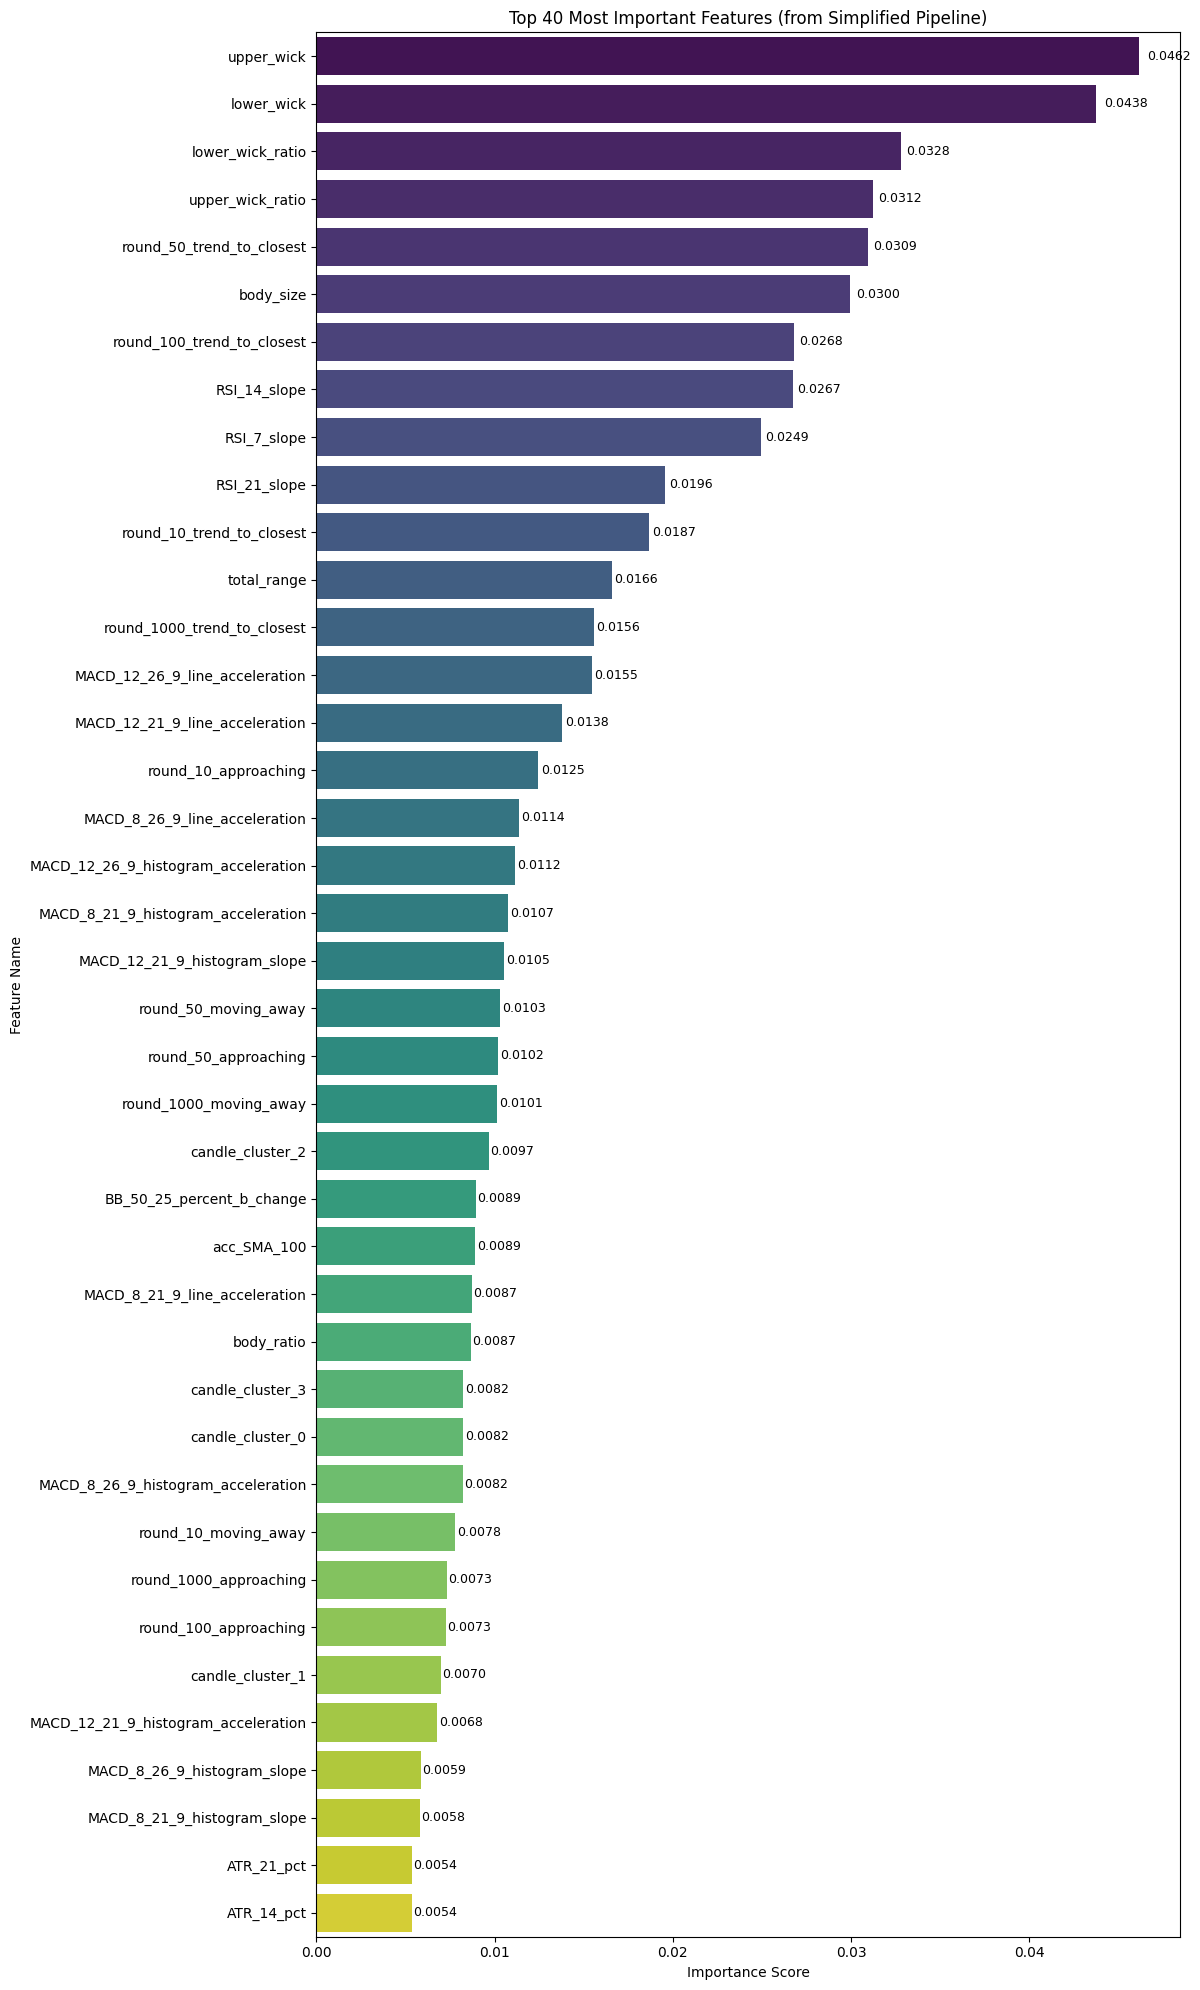


Top 40 features by importance:
                                 Feature  Importance
496                           upper_wick    0.046159
497                           lower_wick    0.043769
501                     lower_wick_ratio    0.032788
500                     upper_wick_ratio    0.031235
447            round_50_trend_to_closest    0.030942
495                            body_size    0.029968
465           round_100_trend_to_closest    0.026805
55                          RSI_14_slope    0.026732
58                           RSI_7_slope    0.024946
61                          RSI_21_slope    0.019589
429            round_10_trend_to_closest    0.018654
498                          total_range    0.016568
483          round_1000_trend_to_closest    0.015559
138       MACD_12_26_9_line_acceleration    0.015459
163       MACD_12_21_9_line_acceleration    0.013802
430                 round_10_approaching    0.012464
188        MACD_8_26_9_line_acceleration    0.011384
139  MACD_12_2

In [15]:
# --- Reemplazar contenido de la celda 5b5b5a84 ---

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd # Asegurarse que pandas esté importado aquí también
import traceback # Para imprimir errores detallados

print("Analyzing feature importance from the simplified pipeline...")

try:
    # --- Acceder a los componentes del simplified_pipeline ---
    # 1. Acceder al paso de preprocesamiento ('preprocessing')
    preprocessor_step = simplified_pipeline.named_steps['preprocessing']
    # 2. Acceder al clasificador ('classifier')
    classifier_step = simplified_pipeline.named_steps['classifier']

    # --- Obtener nombres de características de cada transformador DENTRO DEL PREPROCESSOR AJUSTADO ---
    all_feature_names = []

    # Obtener la lista de transformadores aplicados y AJUSTADOS
    # transformers_ es una lista de tuplas: (nombre, transformador_ajustado, columnas)
    transformers_applied = preprocessor_step.transformers_

    for name, fitted_transformer_obj, columns in transformers_applied:
        if fitted_transformer_obj == 'drop' or fitted_transformer_obj == 'passthrough':
            continue # Saltar si es 'drop' o 'passthrough'

        print(f"  Processing transformer: '{name}' applied to {len(columns)} columns")

        # Caso 1: Transformador Numérico ('num')
        if name == 'num':
            # Los nombres son las columnas originales
            if 'final_numerical_features' not in locals():
                 raise NameError("Variable 'final_numerical_features' not found. Did cell 7c0ee38a run?")
            all_feature_names.extend(final_numerical_features)
            print(f"    Added {len(final_numerical_features)} numerical features.")

        # Caso 2: Transformador Categórico OHE ('cat_ohe')
        elif name == 'cat_ohe':
            # *** CORRECCIÓN AQUÍ ***
            # Acceder al OneHotEncoder DENTRO del TRANSFORMADOR AJUSTADO ('fitted_transformer_obj')
            # Este 'fitted_transformer_obj' es el Pipeline ('imputer', 'onehot') que fue ajustado.
            try:
                onehot_encoder_fitted = fitted_transformer_obj.named_steps['onehot']
            except KeyError:
                 raise KeyError(f"Could not find step 'onehot' within the fitted transformer named '{name}'. Check pipeline definition in cell 984e01f7.")
            except AttributeError:
                 raise AttributeError(f"The fitted transformer named '{name}' does not seem to be a Pipeline object with named steps. Check ColumnTransformer setup.")

            # Obtener nombres usando las columnas originales
            if 'other_categorical_features' not in locals():
                 raise NameError("Variable 'other_categorical_features' not found. Did cell 7c0ee38a run?")
            # Usar el encoder AJUSTADO para obtener los nombres
            ohe_feature_names = onehot_encoder_fitted.get_feature_names_out(other_categorical_features)
            all_feature_names.extend(ohe_feature_names)
            print(f"    Added {len(ohe_feature_names)} OHE features.")

        # Caso 3: Transformador de Embedding de Patrones ('pattern_embed')
        elif name == 'pattern_embed':
            # El último paso es TruncatedSVD. Los nombres son generados, no dependen del SVD ajustado directamente.
            if 'N_EMBEDDING_COMPONENTS' not in locals():
                 raise NameError("Variable 'N_EMBEDDING_COMPONENTS' not found. Did cell 984e01f7 run?")
            svd_feature_names = [f"pattern_svd_{i}" for i in range(N_EMBEDDING_COMPONENTS)]
            all_feature_names.extend(svd_feature_names)
            print(f"    Added {len(svd_feature_names)} SVD embedding features.")

        # Añadir lógica para otros transformadores si los hubiera
        else:
            print(f"    Warning: Unhandled transformer type '{name}'. Attempting generic name extraction.")
            try:
                # Intento genérico usando el transformador ajustado
                generic_names = fitted_transformer_obj.get_feature_names_out(columns)
                all_feature_names.extend(generic_names)
                print(f"    Attempted generic names: Added {len(generic_names)} features.")
            except AttributeError:
                print(f"    Could not get feature names for transformer '{name}'.")


    print(f"\nTotal features generated by preprocessor: {len(all_feature_names)}")

    # --- Obtener Importancias ---
    # Obtener las importancias del clasificador ya ajustado
    importances = classifier_step.feature_importances_
    print(f"Number of importances found from classifier: {len(importances)}")

    # Verificar que el número de nombres y de importancias coincida
    if len(all_feature_names) != len(importances):
        print(f"DEBUG: First 10 expected names: {all_feature_names[:10]}")
        print(f"DEBUG: Last 10 expected names: {all_feature_names[-10:]}")
        raise ValueError(f"CRITICAL ERROR: Mismatch between number of generated feature names ({len(all_feature_names)}) and feature importances from the model ({len(importances)}). Check ColumnTransformer steps and feature lists.")

    # --- Crear DataFrame y Visualizar ---
    importance_df = pd.DataFrame({
        'Feature': all_feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)

    top_n = 40
    top_features = importance_df.head(top_n)

    plt.figure(figsize=(12, max(8, top_n // 2)))
    ax = sns.barplot(x='Importance', y='Feature', data=top_features, palette='viridis')
    plt.title(f'Top {top_n} Most Important Features (from Simplified Pipeline)')
    plt.xlabel('Importance Score')
    plt.ylabel('Feature Name')
    plt.tight_layout()

    for i, v in enumerate(top_features['Importance']):
         ax.text(v * 1.01, i, f'{v:.4f}', va='center', fontsize=9)

    plt.show()

    print(f"\nTop {top_n} features by importance:")
    print(top_features.to_string())

except NameError as ne:
    print(f"Error: Could not find a required variable (like 'simplified_pipeline', 'final_numerical_features', etc.). Did the previous cells run correctly? Details: {ne}")
    traceback.print_exc()
except AttributeError as ae:
     print(f"Error accessing parts of the pipeline or transformers. Check step names ('preprocessing', 'classifier') and transformer names ('num', 'cat_ohe', 'pattern_embed', 'onehot', 'svd'). Details: {ae}")
     traceback.print_exc()
except ValueError as ve:
     print(f"ValueError during importance analysis: {ve}")
     traceback.print_exc()
except Exception as e:
    print(f"An unexpected error occurred while extracting or plotting feature importances: {e}")
    traceback.print_exc()

In [16]:
print("Calculando pips promedio para resultados 'SIN_ALCANCE' en el conjunto de prueba...")

# Verificar que las columnas necesarias existan en df_test
required_cols_sa = ['compra_resultado', 'compra_pips', 'venta_resultado', 'venta_pips']
if not all(col in df_test.columns for col in required_cols_sa):
    raise KeyError(f"Error: df_test no contiene todas las columnas necesarias {required_cols_sa}. Asegúrate que la celda 5fb60a74 se ejecutó correctamente.")

# Filtrar df_test para obtener los pips de los casos SIN_ALCANCE para compras
pips_compra_sin_alcance = df_test.loc[df_test['compra_resultado'] == 'SIN_ALCANCE', 'compra_pips']
print(f"  Encontrados {len(pips_compra_sin_alcance)} casos 'SIN_ALCANCE' para compras.")

# Filtrar df_test para obtener los pips de los casos SIN_ALCANCE para ventas
pips_venta_sin_alcance = df_test.loc[df_test['venta_resultado'] == 'SIN_ALCANCE', 'venta_pips']
print(f"  Encontrados {len(pips_venta_sin_alcance)} casos 'SIN_ALCANCE' para ventas.")

# Combinar los pips de compra y venta en una sola Serie
todos_pips_sin_alcance = pd.concat([pips_compra_sin_alcance, pips_venta_sin_alcance], ignore_index=True)

# Calcular la media si hay datos
if not todos_pips_sin_alcance.empty:
    # Eliminar posibles NaNs en los pips antes de calcular la media
    todos_pips_sin_alcance_validos = todos_pips_sin_alcance.dropna()
    if not todos_pips_sin_alcance_validos.empty:
        PIPS_SIN_ALCANCE_VALOR = todos_pips_sin_alcance_validos.mean()
        print(f"PIPS_SIN_ALCANCE_VALOR calculado (promedio de pips en casos 'SIN_ALCANCE'): {PIPS_SIN_ALCANCE_VALOR:.4f}")
    else:
        print("Advertencia: No se encontraron valores de pips válidos para los casos 'SIN_ALCANCE'. Estableciendo PIPS_SIN_ALCANCE_VALOR a 0.0")
        PIPS_SIN_ALCANCE_VALOR = 0.0
else:
    print("Advertencia: No se encontraron resultados 'SIN_ALCANCE' en el conjunto de prueba. Estableciendo PIPS_SIN_ALCANCE_VALOR a 0.0")
    PIPS_SIN_ALCANCE_VALOR = 0.0

Calculando pips promedio para resultados 'SIN_ALCANCE' en el conjunto de prueba...
  Encontrados 14875 casos 'SIN_ALCANCE' para compras.
  Encontrados 14151 casos 'SIN_ALCANCE' para ventas.
PIPS_SIN_ALCANCE_VALOR calculado (promedio de pips en casos 'SIN_ALCANCE'): 1.9787


# Analizar Métricas por Umbral de Probabilidad

Obtener las probabilidades predichas para el conjunto de prueba (`predict_proba`). Usar la función `analizar_metricas_por_umbral` para evaluar el rendimiento (profit, precisión, pips promedio) en diferentes umbrales para decisiones de compra y venta. Esto ayuda a determinar umbrales óptimos para generar señales de trading basadas en la confianza del modelo.

Analyzing performance by probability threshold...
   Predicting probabilities on the engineered test set...
   Model classes order: ['no_objetivo_alcanzado' 'objetivo_compra_alcanzado'
 'objetivo_venta_alcanzado']
   Aligning test data for analysis...
   Aligned test data shape: (72174, 24)
   Running threshold analysis function (analizar_metricas_por_umbral)...
   Using pip_objetivo=8, pip_stop=2, pip_sin_alcance=1.9787 for analysis.
Buy Strategy Metrics:


,threshold,precision,total_trades,profit,avg_pips
0,0.10,9.35%,"55,936","-3,665",-0.07
1,0.15,10.34%,"48,711",-133,-0.00
2,0.20,11.62%,"40,186",937,0.02
3,0.25,13.27%,"31,358","1,710",0.05
4,0.30,15.15%,"23,412","2,227",0.10
5,0.35,16.85%,"17,563","2,511",0.14
6,0.40,18.28%,"13,687","2,759",0.20
7,0.45,19.98%,"10,584","3,288",0.31
8,0.50,21.87%,"7,599","3,304",0.43
9,0.55,24.90%,"4,714","3,183",0.68



Sell Strategy Metrics:


,threshold,precision,total_trades,profit,avg_pips
0,0.10,9.38%,"56,248","-5,218",-0.09
1,0.15,10.15%,"50,206","-2,117",-0.04
2,0.20,11.33%,"42,108","-1,348",-0.03
3,0.25,12.87%,"33,153",-589,-0.02
4,0.30,14.95%,"25,103","1,257",0.05
5,0.35,16.66%,"19,113","2,170",0.11
6,0.40,17.98%,"14,783","2,453",0.17
7,0.45,19.30%,"11,288","2,612",0.23
8,0.50,21.24%,"8,144","3,041",0.37
9,0.55,23.91%,"5,120","2,951",0.58


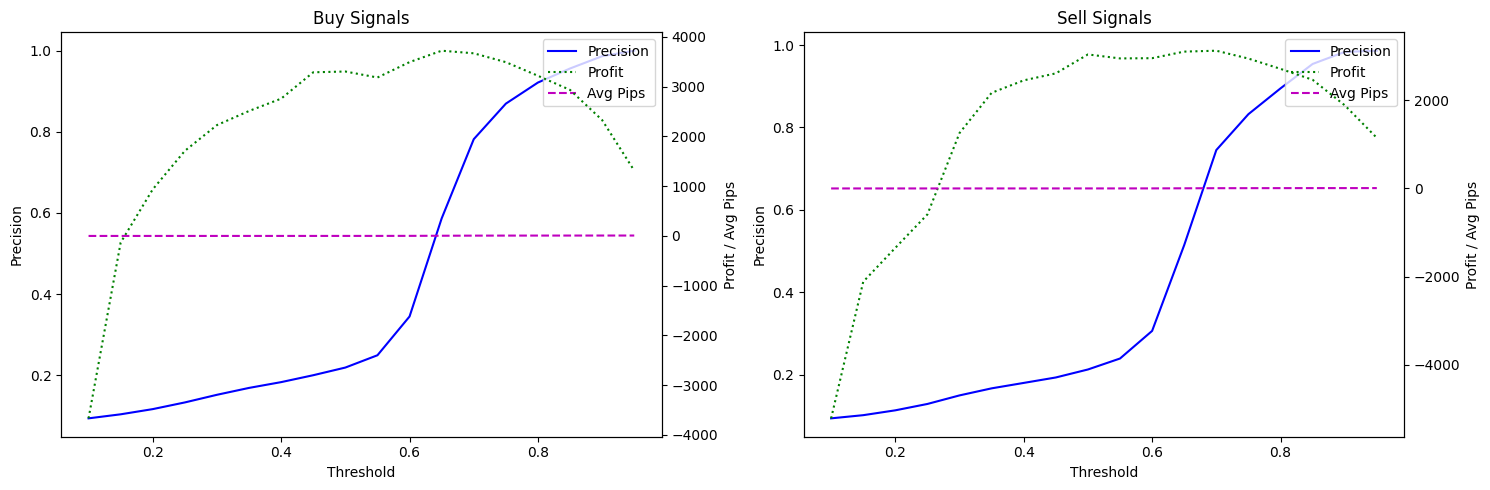


Métricas Mensuales para Compras (Umbral óptimo: 0.65):


,avg_pips,precision,profit,total_trades
month,,,,
2024-01,4.27,62.71%,504,118
2024-02,2.59,45.95%,96,37
2024-03,2.80,48.00%,70,25
2024-04,3.45,53.95%,262,76
2024-05,4.70,65.00%,94,20
2024-06,2.25,42.50%,90,40
2024-07,4.12,57.58%,136,33
2024-08,3.29,52.86%,230,70
2024-09,4.17,60.87%,384,92



Métricas Mensuales para Ventas (Umbral óptimo: 0.70):


,avg_pips,precision,profit,total_trades
month,,,,
2024-01,6.12,81.25%,392,64
2024-02,6.71,85.71%,188,28
2024-03,5.60,76.00%,140,25
2024-04,5.50,75.00%,220,40
2024-05,6.33,83.33%,114,18
2024-06,4.92,69.23%,128,26
2024-07,6.12,81.25%,98,16
2024-08,5.23,72.34%,246,47
2024-09,5.46,72.92%,262,48


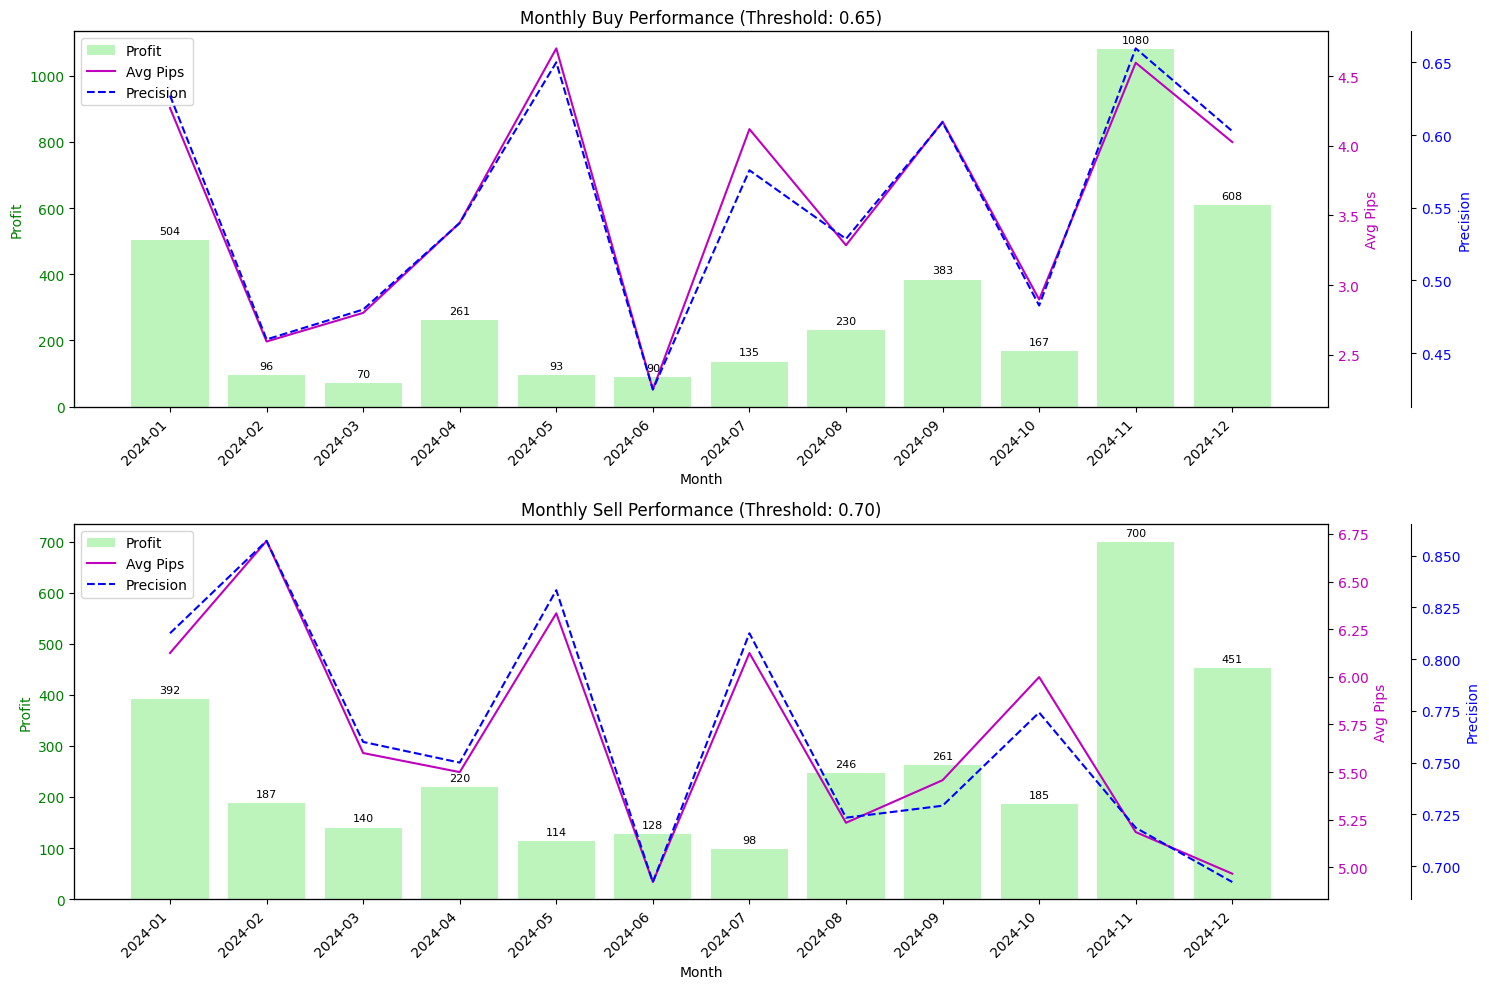

   Threshold analysis function completed.

--- Threshold Analysis Results ---

Best Threshold for Buys (Max Profit):
  Threshold: 0.65
  Profit: 3,722 pips
  Precision: 58.64%
  Avg Pips/Trade: 3.90
  Total Trades: 955.0

Monthly Analysis for Buys (Threshold 0.65):
       month  precision  total_trades   profit  avg_pips
132  2024-01       0.63           118   504.00      4.27
133  2024-02       0.46            37    96.00      2.59
134  2024-03       0.48            25    70.00      2.80
135  2024-04       0.54            76   261.98      3.45
136  2024-05       0.65            20    93.98      4.70
137  2024-06       0.42            40    90.00      2.25
138  2024-07       0.58            33   135.94      4.12
139  2024-08       0.53            70   230.00      3.29
140  2024-09       0.61            92   383.96      4.17
141  2024-10       0.48            58   167.98      2.90
142  2024-11       0.66           235  1080.00      4.60
143  2024-12       0.60           151   608.00    

In [ ]:
# --- Reemplazar contenido de la celda 5e558608 ---

print("Analyzing performance by probability threshold...")
import traceback # Asegurarse que traceback esté importado

try:
    # --- Verificar existencia de variables necesarias ---
    required_vars = ['simplified_pipeline', 'X_engineered_test', 'df_test',
                     'PIPS_OBJETIVO_GENERACION', 'PIPS_STOP_GENERACION', 'PIPS_SIN_ALCANCE_VALOR']
    for var_name in required_vars:
        if var_name not in locals():
            raise NameError(f"Variable '{var_name}' not found. Ensure previous cells (especially data split, training, evaluation, and SIN_ALCANCE calculation) ran correctly.")

    # --- Obtener probabilidades predichas para el conjunto de prueba ---
    print("   Predicting probabilities on the engineered test set...")
    y_pred_proba_test = simplified_pipeline.predict_proba(X_engineered_test)
    class_labels = simplified_pipeline.classes_
    print(f"   Model classes order: {class_labels}") # El orden es importante

    # --- Preparar DataFrame para el análisis ---
    print("   Aligning test data for analysis...")
    required_analysis_cols = ['compra_resultado', 'venta_resultado', 'compra_pips', 'venta_pips', 'datetime']
    if not all(col in df_test.columns for col in required_analysis_cols):
         raise ValueError(f"Error: df_test (from split) is missing required columns for threshold analysis: {required_analysis_cols}")

    # Filtrar df_test para que coincida con las filas usadas en la predicción
    df_test_aligned = df_test.loc[X_engineered_test.index].copy()

    # Verificar que las longitudes coincidan
    if len(df_test_aligned) != len(y_pred_proba_test):
        raise ValueError(f"Mismatch in lengths after alignment: df_test_aligned ({len(df_test_aligned)}) vs y_pred_proba_test ({len(y_pred_proba_test)})")
    print(f"   Aligned test data shape: {df_test_aligned.shape}")

    # --- Ejecutar la función de análisis ---
    print("   Running threshold analysis function (analizar_metricas_por_umbral)...")
    # Nota: La función 'analizar_metricas_por_umbral' asume internamente que
    # y_pred_proba tiene las clases en el orden [?, 'compra', 'venta'].
    # Verificar la salida de 'Model classes order' para confirmar.
    print(f"   Using pip_objetivo={PIPS_OBJETIVO_GENERACION}, pip_stop={PIPS_STOP_GENERACION}, pip_sin_alcance={PIPS_SIN_ALCANCE_VALOR:.4f} for analysis.")

    # Importar la función si no está ya en el scope (mejor práctica)
    from utils.viz_utils import analizar_metricas_por_umbral

    compra_df, venta_df, compra_mensual_df, venta_mensual_df = analizar_metricas_por_umbral(
        y_pred_proba=y_pred_proba_test,
        df_test=df_test_aligned,
        pip_objetivo=PIPS_OBJETIVO_GENERACION,
        pip_stop=PIPS_STOP_GENERACION,
        pip_sin_alcance=PIPS_SIN_ALCANCE_VALOR,
        # Asegúrate que la función use el orden correcto de class_labels si es necesario
        # class_labels=class_labels # Descomentar si la función acepta este argumento
    )
    print("   Threshold analysis function completed.")

    # --- Mostrar Resultados ---
    print("\n--- Threshold Analysis Results ---")

    # Encontrar y mostrar mejor umbral para compras (basado en profit)
    if not compra_df.empty:
        # Asegurarse que 'profit' existe antes de buscar el máximo
        if 'profit' in compra_df.columns:
            mejor_umbral_compra = compra_df.loc[compra_df['profit'].idxmax()]
            print(f"\nBest Threshold for Buys (Max Profit):")
            print(f"  Threshold: {mejor_umbral_compra.get('threshold', 'N/A'):.2f}")
            print(f"  Profit: {mejor_umbral_compra.get('profit', 'N/A'):,.0f} pips")
            print(f"  Precision: {mejor_umbral_compra.get('precision', 'N/A'):.2%}")
            print(f"  Avg Pips/Trade: {mejor_umbral_compra.get('avg_pips', 'N/A'):.2f}")
            print(f"  Total Trades: {mejor_umbral_compra.get('total_trades', 'N/A')}")

            # Mostrar desglose mensual para el mejor umbral de compra
            umbral_optimo_compra = mejor_umbral_compra.get('threshold')
            if umbral_optimo_compra is not None and not compra_mensual_df.empty:
                analisis_mensual_compra = compra_mensual_df[compra_mensual_df['threshold'] == umbral_optimo_compra]
                print(f"\nMonthly Analysis for Buys (Threshold {umbral_optimo_compra:.2f}):")
                if 'month' in analisis_mensual_compra.columns:
                     print(analisis_mensual_compra.sort_values('month')[['month', 'precision', 'total_trades', 'profit', 'avg_pips']].round(2).to_string())
                else:
                     print("Warning: 'month' column not found in compra_mensual_df for sorting.")
                     print(analisis_mensual_compra[['precision', 'total_trades', 'profit', 'avg_pips']].round(2).to_string())
            elif compra_mensual_df.empty:
                 print("\nMonthly analysis data for buys is empty.")
        else:
            print("\n'profit' column not found in compra_df.")
    else:
        print("\nNo buy trades found for analysis (compra_df is empty).")


    # Encontrar y mostrar mejor umbral para ventas (basado en profit)
    if not venta_df.empty:
         if 'profit' in venta_df.columns:
            mejor_umbral_venta = venta_df.loc[venta_df['profit'].idxmax()]
            print(f"\nBest Threshold for Sells (Max Profit):")
            print(f"  Threshold: {mejor_umbral_venta.get('threshold', 'N/A'):.2f}")
            print(f"  Profit: {mejor_umbral_venta.get('profit', 'N/A'):,.0f} pips")
            print(f"  Precision: {mejor_umbral_venta.get('precision', 'N/A'):.2%}")
            print(f"  Avg Pips/Trade: {mejor_umbral_venta.get('avg_pips', 'N/A'):.2f}")
            print(f"  Total Trades: {mejor_umbral_venta.get('total_trades', 'N/A')}")

            # Mostrar desglose mensual para el mejor umbral de venta
            umbral_optimo_venta = mejor_umbral_venta.get('threshold')
            if umbral_optimo_venta is not None and not venta_mensual_df.empty:
                analisis_mensual_venta = venta_mensual_df[venta_mensual_df['threshold'] == umbral_optimo_venta]
                print(f"\nMonthly Analysis for Sells (Threshold {umbral_optimo_venta:.2f}):")
                if 'month' in analisis_mensual_venta.columns:
                    print(analisis_mensual_venta.sort_values('month')[['month', 'precision', 'total_trades', 'profit', 'avg_pips']].round(2).to_string())
                else:
                    print("Warning: 'month' column not found in venta_mensual_df for sorting.")
                    print(analisis_mensual_venta[['precision', 'total_trades', 'profit', 'avg_pips']].round(2).to_string())
            elif venta_mensual_df.empty:
                 print("\nMonthly analysis data for sells is empty.")
         else:
            print("\n'profit' column not found in venta_df.")
    else:
         print("\nNo sell trades found for analysis (venta_df is empty).")


except NameError as ne:
    print(f"Error: A required variable might not be defined. {ne}")
    traceback.print_exc()
except ValueError as ve:
    print(f"ValueError during threshold analysis preparation or execution: {ve}")
    traceback.print_exc()
except ImportError as ie:
    print(f"ImportError: Could not import 'analizar_metricas_por_umbral'. Check utils/viz_utils.py. Details: {ie}")
    traceback.print_exc()
except Exception as e:
    print(f"An unexpected error occurred during threshold analysis: {e}")
    traceback.print_exc()

# Guardar el Modelo Entrenado

Guardar el objeto Pipeline entrenado completo en un archivo usando `joblib.dump`. Esto permite recargar el pipeline más tarde para hacer predicciones sobre nuevos datos sin necesidad de reentrenar.

In [18]:
# --- Reemplazar contenido de la celda 12f4e2fc ---

import os
import joblib
import json
import traceback

print("--- Model Saving Cell ---")

# Verificar si el modelo fue cargado o recién entrenado (variable definida en celda 7c0ee38a)
if 'model_loaded' in locals() and model_loaded:
    print("Model was loaded from existing files. Skipping saving.")
else:
    # Proceder a guardar solo si se entrenó un nuevo modelo
    print("Model was newly trained. Attempting to save pipeline, clusterer, and metadata...")

    # Verificar que las variables a guardar existan y no sean None
    # Estas variables DEBEN haber sido creadas en la celda 7c0ee38a si model_loaded es False
    if 'simplified_pipeline' not in locals() or simplified_pipeline is None:
        print("Error: 'simplified_pipeline' not found or is None. Cannot save.")
    elif 'fitted_clusterer' not in locals() or fitted_clusterer is None:
        print("Error: 'fitted_clusterer' not found or is None. Cannot save.")
    elif 'metadata' not in locals() or metadata is None:
        # 'metadata' ya debe contener las listas de features si se entrenó
        print("Error: 'metadata' dictionary (prepared during training) not found or is None. Cannot save.")
    else:
        try:
            # Asegurar que el directorio exista (model_dir definido en celda 7c0ee38a)
            os.makedirs(model_dir, exist_ok=True)

            # 1. Guardar el pipeline (model_filepath definido en celda 7c0ee38a)
            joblib.dump(simplified_pipeline, model_filepath)
            print(f"  - Pipeline saved successfully to: {model_filepath}")

            # 2. Guardar el clusterer ajustado (clusterer_filepath definido en celda 7c0ee38a)
            joblib.dump(fitted_clusterer, clusterer_filepath)
            print(f"  - Fitted clusterer saved successfully to: {clusterer_filepath}")

            # 3. Guardar metadata (usar el diccionario 'metadata' ya preparado en la celda 7c0ee38a)
            # Este diccionario ya contiene las listas 'final_numerical_features', etc.
            # (metadata_filepath definido en celda 7c0ee38a)
            with open(metadata_filepath, 'w') as f:
                json.dump(metadata, f, indent=4) # Guardar el diccionario 'metadata' existente
            print(f"  - Metadata saved successfully to: {metadata_filepath}")

            print("\nModel, clusterer, and metadata saved successfully.")

        except NameError as ne:
             print(f"Error saving: A required variable (like model_dir, model_filepath, etc.) might not be defined. {ne}")
             traceback.print_exc()
        except Exception as e:
            print(f"\nError saving the pipeline, clusterer, or metadata: {e}")
            traceback.print_exc()

# Mensaje final de la celda
print("--- Model Saving Cell Finished ---")

# Comentario: El código de ejemplo para cargar se mantiene igual
# Example of how to load the pipeline and clusterer later:
# loaded_pipeline = joblib.load(model_filepath)
# loaded_clusterer = joblib.load(clusterer_filepath)
# with open(metadata_filepath, 'r') as f:
#     loaded_metadata = json.load(f)
# print("Pipeline, clusterer and metadata loaded successfully.")
# # Remember to apply the SAME feature engineering steps before predicting
# # X_new_engineered, _ = engineer_features(X_new_raw,
# #                                         n_candles=loaded_metadata['n_candles_param'],
# #                                         n_clusters=loaded_metadata['n_clusters_param'],
# #                                         clusterer=loaded_clusterer,
# #                                         fit_clusterer=False)
# # new_predictions = loaded_pipeline.predict(X_new_engineered)


--- Model Saving Cell ---
Model was newly trained. Attempting to save pipeline, clusterer, and metadata...
  - Pipeline saved successfully to: ../models\forex_rf_pipeline_eurusd_5min.joblib
  - Fitted clusterer saved successfully to: ../models\forex_candle_clusterer_eurusd_5min.joblib
  - Metadata saved successfully to: ../models\forex_rf_pipeline_eurusd_5min_metadata.json

Model, clusterer, and metadata saved successfully.
--- Model Saving Cell Finished ---


# Evaluar Rendimiento en Conjunto Out-of-Time (OOT)

Aplicar la ingeniería de características al conjunto OOT usando el `fitted_clusterer` y evaluar el rendimiento del `simplified_pipeline` final en estos datos no vistos durante el entrenamiento ni la validación inicial. Esto da una estimación más realista del rendimiento futuro.

--- OOT Evaluation Cell ---

Applying feature engineering to OOT set (X_oot)...
--- Starting Feature Engineering ---
>>> Starting step: apply_technical_indicators


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1012: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_shrinking_histogram_above_zero"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1019: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{base_name}_buy_signal"] = (
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:1024: PerformanceW

<<< Finished step: apply_technical_indicators
>>> Starting step: apply_candle_features (n_candles=15)
<<< Finished step: apply_candle_features
   Transforming with PROVIDED CandleClusterer...
>>> Starting step: CandleClusterer.transform
   Candle clusters predicted.


c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:626: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result_df[f'{feature}_lag{i}'] = df[feature].shift(i)
c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:

   Basic patterns created.
   No pattern mapping to apply (or mapping is empty).
<<< Finished step: CandleClusterer.transform
>>> Starting step: replace_inf_with_nan
  Columns initially identified as numeric: ['open', 'high', 'low', 'close', 'volume', 'barCount', 'Year', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'compra_velas', 'compra_pips', 'venta_velas', 'venta_pips', 'SMA_10', 'SMA_40', 'SMA_100', 'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10', 'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10', 'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40', 'sma_order_score', 'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100', 'diff_slope_SMA_10_slope_SMA_40', 'diff_slope_SMA_10_slope_SMA_100', 'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100', 'norm_diff_SMA_40_SMA_100', 'close_diff_SMA_10', 'close_diff_SMA_40', 'close_diff_SMA_100', 'crossover', 'sma_spread', 'acc_SMA_10', 'acc_SMA_40', 'acc_SMA_100', 'SMA_10_momentum', 'SMA_10_

,threshold,precision,total_trades,profit,avg_pips
0,0.10,15.84%,"13,399",609,0.05
1,0.15,16.98%,"12,229","2,336",0.19
2,0.20,17.90%,"11,171","3,109",0.28
3,0.25,19.09%,"9,891","3,586",0.36
4,0.30,21.06%,"8,138","3,872",0.48
5,0.35,22.81%,"6,559","3,716",0.57
6,0.40,24.62%,"5,446","3,779",0.69
7,0.45,27.07%,"4,522","3,996",0.88
8,0.50,29.48%,"3,579","3,834",1.07
9,0.55,34.09%,"2,479","3,699",1.49



Sell Strategy Metrics:


,threshold,precision,total_trades,profit,avg_pips
0,0.10,16.28%,"13,628","1,401",0.10
1,0.15,17.48%,"12,472","3,019",0.24
2,0.20,18.57%,"11,248","3,753",0.33
3,0.25,20.33%,"9,766","4,456",0.46
4,0.30,21.99%,"8,300","4,602",0.55
5,0.35,23.80%,"6,913","4,522",0.65
6,0.40,25.71%,"5,760","4,535",0.79
7,0.45,27.98%,"4,761","4,626",0.97
8,0.50,31.38%,"3,716","4,745",1.28
9,0.55,36.26%,"2,639","4,547",1.72


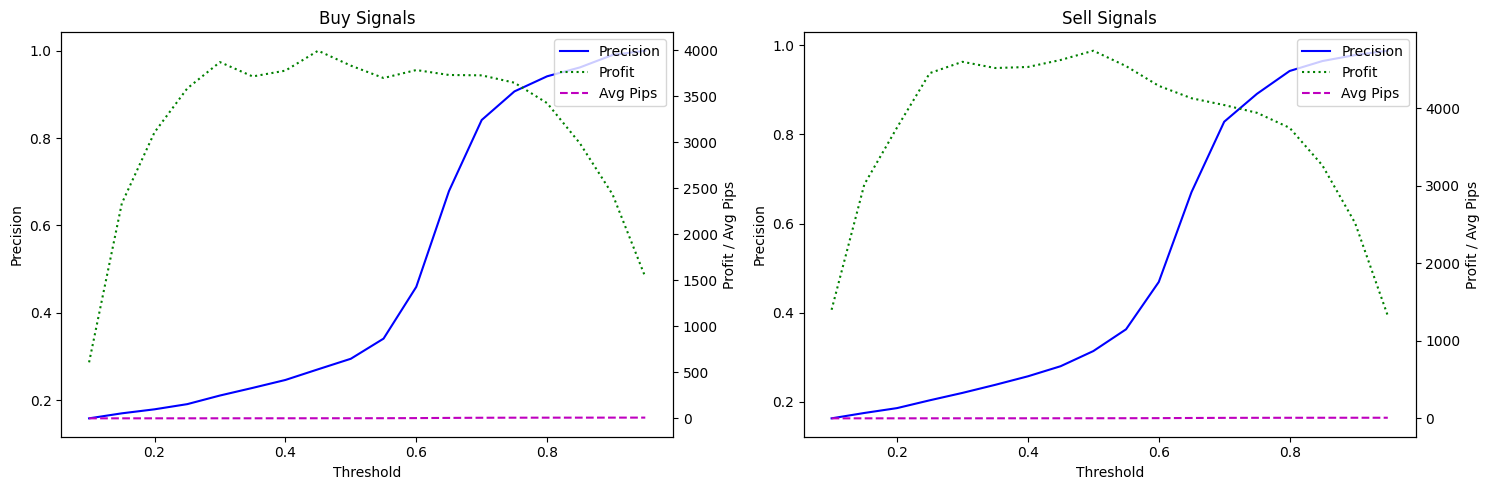

Mejor umbral para Compras (max profit ajustado por costo=0.2): 0.70 (Profit Ajustado: 3611.96)
Mejor umbral para Ventas (max profit ajustado por costo=0.2): 0.55 (Profit Ajustado: 4018.84)

Métricas Mensuales para Compras (Umbral seleccionado: 0.70):


,avg_pips,precision,profit,total_trades
month,,,,
2025-01,5.98,79.49%,700,117
2025-02,5.94,79.37%,374,63
2025-03,5.62,76.00%,984,175
2025-04,7.42,94.22%,"1,670",225



Métricas Mensuales para Ventas (Umbral seleccionado: 0.55):


,avg_pips,precision,profit,total_trades
month,,,,
2025-01,1.41,33.17%,866,615
2025-02,1.09,29.42%,642,588
2025-03,1.09,30.18%,"1,030",941
2025-04,4.06,59.80%,"2,010",495


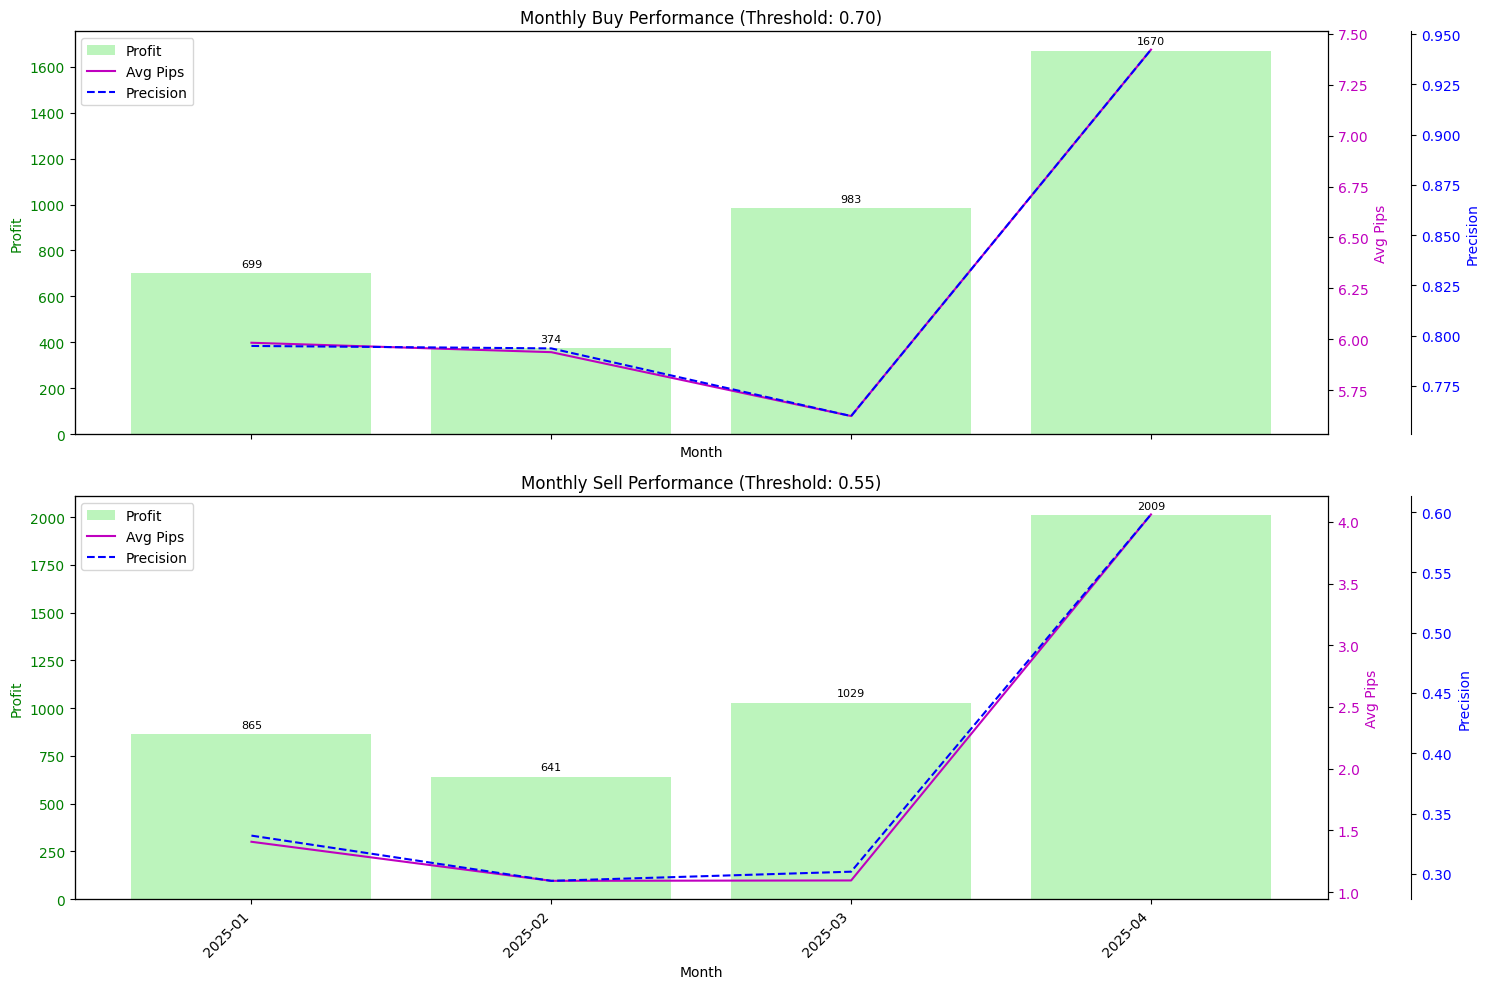

   OOT Threshold analysis function completed.

--- OOT Evaluation Cell Finished ---


In [22]:
# --- Celda para Evaluación OOT ---
import utils.viz_utils
importlib.reload(utils.viz_utils)
from utils.viz_utils import analizar_metricas_por_umbral
import traceback
from sklearn.metrics import classification_report, accuracy_score
# Asegúrate que la función de análisis esté disponible si la vas a usar
# from utils.viz_utils import analizar_metricas_por_umbral

print("--- OOT Evaluation Cell ---")

try:
    # --- Verificar existencia de variables necesarias ---
    required_vars_oot = ['simplified_pipeline', 'fitted_clusterer', 'X_oot', 'y_oot', 'df_oot',
                         'N_CANDLES_PARAM', 'N_CLUSTERS_PARAM',
                         'PIPS_OBJETIVO_GENERACION', 'PIPS_STOP_GENERACION', 'PIPS_SIN_ALCANCE_VALOR']
    for var_name in required_vars_oot:
        if var_name not in locals():
            raise NameError(f"Variable OOT '{var_name}' not found. Ensure previous cells ran correctly.")

    # --- 1. Aplicar Ingeniería de Características a X_oot ---
    print("\nApplying feature engineering to OOT set (X_oot)...")
    X_engineered_oot, _ = engineer_features(
        X_oot,
        n_candles=N_CANDLES_PARAM,
        n_clusters=N_CLUSTERS_PARAM,
        clusterer=fitted_clusterer, # Usar el clusterer ajustado
        fit_clusterer=False       # NO reajustar
    )
    print(f"Shape after external engineering (OOT): {X_engineered_oot.shape}")

    # --- 2. Alinear y_oot ---
    # Alinear y_oot con las filas que sobrevivieron a la ingeniería
    y_oot_aligned = y_oot.loc[X_engineered_oot.index]
    print(f"Shape of y_oot_aligned: {y_oot_aligned.shape}")

    # --- 3. Evaluar usando el Pipeline Simplificado (Predicciones y Métricas) ---
    print("\nEvaluating model performance on OOT set using simplified pipeline...")

    # Predecir clases en conjunto OOT (ingenierizado)
    y_pred_oot = simplified_pipeline.predict(X_engineered_oot)
    acc_oot = accuracy_score(y_oot_aligned, y_pred_oot)

    print("\n=== Reporte de Clasificación - Conjunto OOT ===\n")
    print(f"Length check: y_oot_aligned={len(y_oot_aligned)}, y_pred_oot={len(y_pred_oot)}")
    if len(y_oot_aligned) == len(y_pred_oot):
        print(classification_report(y_oot_aligned, y_pred_oot))
        print(f"Accuracy OOT: {acc_oot:.4f}\n")
    else:
        print("Error: Length mismatch between y_oot_aligned and y_pred_oot. Cannot generate report.")


    # --- 4. (Opcional) Análisis por Umbral de Probabilidad en OOT ---
    print("\nPredicting probabilities on OOT set for threshold analysis...")
    y_pred_proba_oot = simplified_pipeline.predict_proba(X_engineered_oot)
    class_labels_oot = simplified_pipeline.classes_ # Deberían ser las mismas
    print(f"   Model classes order (OOT check): {class_labels_oot}")

    # Preparar df_oot alineado
    print("   Aligning OOT data (df_oot) for analysis...")
    required_analysis_cols_oot = ['compra_resultado', 'venta_resultado', 'compra_pips', 'venta_pips', 'datetime']
    if not all(col in df_oot.columns for col in required_analysis_cols_oot):
         raise ValueError(f"Error: df_oot is missing required columns for threshold analysis: {required_analysis_cols_oot}")

    df_oot_aligned = df_oot.loc[X_engineered_oot.index].copy()

    if len(df_oot_aligned) != len(y_pred_proba_oot):
        raise ValueError(f"Mismatch in lengths for OOT analysis: df_oot_aligned ({len(df_oot_aligned)}) vs y_pred_proba_oot ({len(y_pred_proba_oot)})")
    print(f"   Aligned OOT data shape: {df_oot_aligned.shape}")

    print("\n   Running threshold analysis function on OOT data...")
    print(f"   Using pip_objetivo={PIPS_OBJETIVO_GENERACION}, pip_stop={PIPS_STOP_GENERACION}, pip_sin_alcance={PIPS_SIN_ALCANCE_VALOR:.4f} for OOT analysis.")

    # Asegúrate que la función esté importada
    from utils.viz_utils import analizar_metricas_por_umbral

    # Ejecutar análisis (esto también mostrará tablas y gráficos para OOT)
    compra_df_oot, venta_df_oot, compra_mensual_df_oot, venta_mensual_df_oot = analizar_metricas_por_umbral(
        y_pred_proba=y_pred_proba_oot,
        df_test=df_oot_aligned, # Pasar el dataframe OOT alineado
        pip_objetivo=PIPS_OBJETIVO_GENERACION,
        pip_stop=PIPS_STOP_GENERACION,
        pip_sin_alcance=PIPS_SIN_ALCANCE_VALOR,
        # class_labels=class_labels_oot # Descomentar si la función lo soporta
    )
    print("   OOT Threshold analysis function completed.")


except NameError as ne:
     print(f"\nERROR in OOT Evaluation: A required variable might not be defined. {ne}")
     traceback.print_exc()
except ValueError as ve:
     print(f"\nERROR in OOT Evaluation: ValueError occurred. {ve}")
     traceback.print_exc()
except ImportError as ie:
     print(f"\nERROR in OOT Evaluation: ImportError. Could not import a required function (e.g., 'analizar_metricas_por_umbral'). {ie}")
     traceback.print_exc()
except Exception as e:
    print(f"\nAn unexpected error occurred during OOT evaluation: {e}")
    traceback.print_exc()

print("\n--- OOT Evaluation Cell Finished ---")